In [1]:
import ot
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
import math
import scipy
from scipy.spatial import cKDTree
from scipy import integrate
from scipy import interpolate
from scipy.spatial import Delaunay
from scipy.spatial import Voronoi
from itertools import product
import torch
torch.manual_seed(100000)
import torch.nn as nn
import torch.optim as optim

np.random.seed(100000)  # NEW: keep the noisy data and sampled indices fixed

In [2]:
# settings
start = np.array((0., 1., 1.05))
dt = 0.01
subset_size = 20  # cell number
slope = 0.5  # original weighting parameter (epsilon = 1/slope)
traj_length = int(1e7)
noise_level = 0.5
sample_size = int(500)
epsilon = 1e-4  # original teleportation parameter (not the weighting epsilon)
sampling_time = 1
simulation_t = int(2e4)
steps = 5
N_iters = 10000

# NEW: ablation settings
eps_values = np.linspace(1, 19, 10)#[1.0, 1.25, 1.5, 2.0, 2.5]#weighting parameter #2 in manuscript
mesh_shape = (2, 2, 5)  # 20 uniform centers
n_trials = 10
invert_variables = [0]  # Hybrid model; use [0, 1, 2] to learn all derivatives.
ot_max_iter = 1000000

In [12]:
def Lorenz(x):
    x = x.T
    return np.array((10 * (x[1] - x[0]),
                     x[0] * (28 - x[2]) - x[1],
                     x[0] * x[1] - (8/3) * x[2])).T


def Lorenz_vec(x):
    return torch.stack((10 * (x[:, 1] - x[:, 0]),
                        x[:, 0] * (28 - x[:, 2]) - x[:, 1],
                        x[:, 0] * x[:, 1] - (8/3) * x[:, 2]), dim=1)


def traj(length, starts=start, model=Lorenz):
    x = starts
    values = np.zeros((length, len(starts)))
    values[0] = x
    for i in range(length - 1):
        x = x + dt * model(x)
        values[i + 1] = x
    return values


def invariant_measure(matrix):
    N = len(matrix)
    rhs = matrix.new_full((N,), epsilon / N)
    identity = torch.eye(N, dtype=matrix.dtype, device=matrix.device)
    return torch.linalg.solve(identity - (1 - epsilon) * matrix, rhs)


# def w(xs):
#     dists = torch.cdist(xs, Voronoi_centers)
#     if not torch.isfinite(dists).all():
#         raise ValueError("Nonfinite states encountered while computing cell weights.")
#     weights = torch.relu(1 - slope * dists)
#     mass = weights.sum(dim=1, keepdim=True)
#     nearest = nn.functional.one_hot(dists.argmin(dim=1), subset_size).to(weights)
#     denominator = torch.where(mass > 0, mass, torch.ones_like(mass))
#     return torch.where(mass > 0, weights / denominator, nearest)
def w(xs):
    dists = torch.cdist(xs, Voronoi_centers)
    if not torch.isfinite(dists).all():
        raise ValueError("Nonfinite states encountered while computing cell weights.")
    weights = torch.relu(1 - slope * dists)
    mass = weights.sum(dim=1, keepdim=True)
    nearest = nn.functional.one_hot(dists.argmin(dim=1), len(Voronoi_centers)).to(weights)
    denominator = torch.where(mass > 0, mass, torch.ones_like(mass))
    return torch.where(mass > 0, weights / denominator, nearest)

def Ulam(points, Tpoints):
    with torch.no_grad():
        indices = torch.as_tensor(tree.query(points.detach().cpu().numpy())[1],
                                  dtype=torch.long, device=points.device)
    weights = w(Tpoints).to(torch.float64)
    # Empty source cells were removed from Voronoi_centers before training.
    # This removes their corresponding destination cells as well.
    n_cells = len(Voronoi_centers)
    mat = weights.new_zeros((n_cells, n_cells))
    mat.index_add_(0, indices, weights)
    mass = mat.sum(dim=1, keepdim=True)
    return (mat / mass).T 
# def Ulam(points, Tpoints):
#     with torch.no_grad():
#         indices = torch.as_tensor(tree.query(points.detach().cpu().numpy())[1],
#                                   dtype=torch.long, device=points.device)
#     weights = w(Tpoints).to(torch.float64)
#     mat = weights.new_zeros((subset_size, subset_size))#Initialize the transition matrix
#     mat.index_add_(0, indices, weights)#add weights to corresponding rows
#     mass = mat.sum(dim=1, keepdim=True)
#     keep = mass.squeeze(1) > 0

#     mat = mat[keep]# Delete zero rows
#     #print(mat)
#     mat = mat / mass[keep]  # Normalize remaining rows
    
#     return mat.T


class W2Loss(torch.autograd.Function):
    @staticmethod
    def forward(ctx, im_net):

        a = np.asarray(im_true_np, dtype=np.float64)
        b = im_net.detach().cpu().numpy().astype(np.float64)
        total_a, total = a.sum(), b.sum()
        a = a / total_a
        b = b / total
        _, log = ot.emd(a, b, MEASURE_OT_COST, log=True)

        # Dual potentials differentiate the cost with respect to normalized b.
        # Apply the chain rule through b = im_net / im_net.sum().
        dual = log["v"]
        gradient = (dual - np.dot(dual, b)) / total
        ctx.save_for_backward(torch.as_tensor(
            gradient, dtype=im_net.dtype, device=im_net.device
        ))
        return im_net.new_tensor(log["cost"])

    @staticmethod
    def backward(ctx, grad_output):
        gradient, = ctx.saved_tensors
        return grad_output * gradient

In [13]:
# Generate data and both fixed partitions once for all trials.
trajectory_clean = traj(traj_length)
trajectory = trajectory_clean + np.random.normal(0, noise_level, (traj_length, 3))
trajectory = trajectory[int(1e4):]
del trajectory_clean

# Every sampled source must have a valid steps-ahead target.
rand_idxs = np.random.choice(len(trajectory) - steps, size=sample_size, replace=False)
randpts = torch.tensor(trajectory[rand_idxs], dtype=torch.float)
Trandpts = torch.tensor(trajectory[rand_idxs + steps], dtype=torch.float)
M_scale = torch.max(torch.abs(randpts))
randpts /= M_scale
Trandpts /= M_scale

adaptive_centers = MiniBatchKMeans(n_clusters=subset_size).fit(randpts).cluster_centers_
assert np.prod(mesh_shape) == subset_size
low, high = randpts.numpy().min(axis=0), randpts.numpy().max(axis=0)
axes = [low[i] + (np.arange(n) + 0.5) * (high[i] - low[i]) / n
        for i, n in enumerate(mesh_shape)]
uniform_centers = np.array(list(product(*axes)), dtype=np.float32)
meshes = {'adaptive': adaptive_centers, 'uniform': uniform_centers}
for method, centers in meshes.items():
    source_ids = cKDTree(centers).query(randpts.detach().cpu().numpy())[1]
    occupied = np.bincount(source_ids, minlength=len(centers)) > 0
    meshes[method] = centers[occupied]
    print(f"{method}: retained {occupied.sum()} of {len(centers)} occupied cells")
scale = M_scale.item()
GT = traj(simulation_t, scale * randpts[0].numpy())
GTpts = torch.tensor(GT[:-steps] / scale, dtype=torch.float)
GTTpts = torch.tensor(GT[steps:], dtype=torch.float)  # Original units.
a = np.ones(simulation_t) / simulation_t

adaptive: retained 20 of 20 occupied cells
uniform: retained 18 of 20 occupied cells


/homes/yinonghyn/.local/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1930: FutureWarning: The default value of `n_init` will change from 3 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=3)


In [14]:
# Reconstruction errors (W2, steps-step RMSE).
def reconstruction_error(net):
    net.eval()
    with torch.no_grad():
        x = randpts[0].clone().reshape(1, 3)
        vals = [x.cpu().numpy().flatten()]
        for _ in range(simulation_t - 1):
            V_field = Lorenz_vec(x * M_scale) / M_scale
            V_field[:, invert_variables] = net(x)[:, invert_variables]
            x = x + dt * V_field
            vals.append(x.cpu().numpy().flatten())
        vals = np.array(vals)

        subGT, subvals = GT, M_scale.item() * vals
        M = ot.dist(subGT, subvals, metric="sqeuclidean")
        costW2, log = ot.emd2(a, a, M, log=True, numItermax=ot_max_iter)
        del M
        costW = float(np.sqrt(costW2))

        netpts = GTpts.clone()
        for _ in range(steps):
            Vf = Lorenz_vec(netpts * M_scale) / M_scale
            Vf[:, invert_variables] = net(netpts)[:, invert_variables]
            netpts = netpts + dt * Vf
        costL = torch.sqrt(torch.mean((M_scale * netpts - GTTpts) ** 2)).item()
    return costW, costL

In [ ]:
# Training: pointwise baseline, then mesh + epsilon loops for measure matching.
results = {
    'adaptive': {eps: [] for eps in eps_values},
    'uniform': {eps: [] for eps in eps_values},
    'pointwise': []
}

for iteration in range(n_trials):
    seed = 100000 + iteration
    # All methods and eps values share the same initialization within each trial.

    # Pointwise (baseline)
    torch.manual_seed(seed)
    net2 = nn.Sequential(
        nn.Linear(3, 100), nn.Tanh(),
        nn.Linear(100, 100), nn.Tanh(),
        nn.Linear(100, 100), nn.Tanh(),
        nn.Linear(100, 3)
    )
    optimizer2 = optim.Adam(net2.parameters(), lr=1e-3)
    net2.train()
    loss2 = []

    with torch.no_grad():
        net2_randpts = randpts.clone()
        for _ in range(steps):
            V_field2 = Lorenz_vec(net2_randpts * M_scale) / M_scale
            V_field2[:, invert_variables] = net2(net2_randpts)[:, invert_variables]
            net2_randpts = net2_randpts + dt * V_field2
        initial_L2 = torch.mean((net2_randpts - Trandpts) ** 2).item()

    for i in range(N_iters):
        optimizer2.zero_grad()
        net2_randpts = randpts.clone()
        for _ in range(steps):
            V_field2 = Lorenz_vec(net2_randpts * M_scale) / M_scale
            V_field2[:, invert_variables] = net2(net2_randpts)[:, invert_variables]
            net2_randpts = net2_randpts + dt * V_field2
        L2 = torch.mean((net2_randpts - Trandpts) ** 2)
        # L2.backward()
        # optimizer2.step()
        # loss2.append(L2.item())
        if i % 500 == 0 and L2.item() < 0.05 * initial_L2:
            break
        L2.backward()
        optimizer2.step()
        loss2.append(L2.item())

    error = reconstruction_error(net2)
    results['pointwise'].append(error)
    print('trial', iteration, 'pointwise W2, RMSE:', error, flush=True)

    # Compare the two fixed partitions at each weighting parameter.
    for method, centers in meshes.items():
        Voronoi_centers = torch.tensor(centers, dtype=torch.float)
        tree = cKDTree(centers)
        centers_np = np.asarray(centers, dtype=np.float64)
        MEASURE_OT_COST = ot.dist(centers_np, centers_np, metric="sqeuclidean")
        for eps in eps_values:
            slope = 1 / eps
            with torch.no_grad():
                U_true = Ulam(randpts, Trandpts)
                im_true = invariant_measure(U_true)
                im_true_np = im_true.cpu().numpy()

            # Our method: match invariant measures.
            torch.manual_seed(seed)
            net1 = nn.Sequential(
                nn.Linear(3, 100), nn.Tanh(),
                nn.Linear(100, 100), nn.Tanh(),
                nn.Linear(100, 100), nn.Tanh(),
                nn.Linear(100, 3)
            )
            optimizer1 = optim.Adam(net1.parameters(), lr=1e-3)
            net1.train()
            loss1 = []

            with torch.no_grad():
                net1_randpts = randpts.clone()
                for _ in range(steps):
                    V_field = Lorenz_vec(net1_randpts * M_scale) / M_scale
                    V_field[:, invert_variables] = net1(net1_randpts)[:, invert_variables]
                    net1_randpts = net1_randpts + dt * V_field
                U_net = Ulam(randpts, net1_randpts)
                im_net = invariant_measure(U_net)
                initial_L1 = W2Loss.apply(im_net).item()

            for i in range(N_iters):
                optimizer1.zero_grad()
                net1_randpts = randpts.clone()
                for _ in range(steps):
                    V_field = Lorenz_vec(net1_randpts * M_scale) / M_scale
                    V_field[:, invert_variables] = net1(net1_randpts)[:, invert_variables]
                    net1_randpts = net1_randpts + dt * V_field
                U_net = Ulam(randpts, net1_randpts)
                im_net = invariant_measure(U_net)
                L1 = W2Loss.apply(im_net)
                # L1.backward()
                # optimizer1.step()
                # loss1.append(L1.item())
                if i % 500 == 0 and L1.item() < 0.05 * initial_L1:
                    break
                L1.backward()
                optimizer1.step()
                loss1.append(L1.item())

            error = reconstruction_error(net1)
            results[method][eps].append(error)
            print('trial', iteration, method, 'eps =', eps,
                  'W2, RMSE:', error, flush=True)

/homes/yinonghyn/.local/lib/python3.10/site-packages/ot/lp/__init__.py:576: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)


trial 0 pointwise W2, RMSE: (3.456816230585461, 0.34275779128074646)
trial 0 adaptive eps = 1.0 W2, RMSE: (3.1222511319514004, 0.28737199306488037)
trial 0 adaptive eps = 3.0 W2, RMSE: (0.8674634534563126, 0.14877289533615112)
trial 0 adaptive eps = 5.0 W2, RMSE: (2.0094020122982634, 0.1340973675251007)
trial 0 adaptive eps = 7.0 W2, RMSE: (0.923740917140188, 0.12326937168836594)
trial 0 adaptive eps = 9.0 W2, RMSE: (1.5660660253865495, 0.12109694629907608)
trial 0 adaptive eps = 11.0 W2, RMSE: (1.8722288516807295, 0.13625109195709229)
trial 0 adaptive eps = 13.0 W2, RMSE: (1.3102759202251373, 0.138321191072464)
trial 0 adaptive eps = 15.0 W2, RMSE: (1.2636030069970512, 0.12661132216453552)
trial 0 adaptive eps = 17.0 W2, RMSE: (3.21224438182833, 0.13431468605995178)
trial 0 adaptive eps = 19.0 W2, RMSE: (1.5295317740131242, 0.12707816064357758)
trial 0 uniform eps = 1.0 W2, RMSE: (18.40682448878516, 0.8849321007728577)
trial 0 uniform eps = 3.0 W2, RMSE: (19.37235214778965, 1.00989282

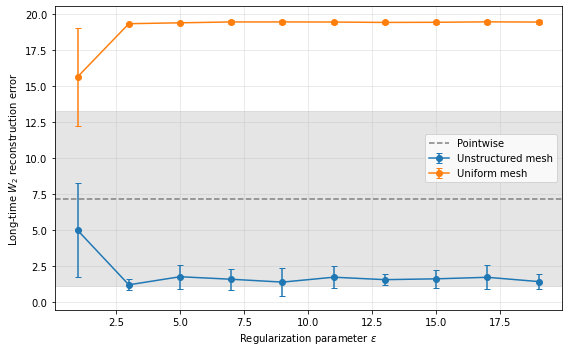

In [17]:
metric = 0
plt.figure(figsize=(8, 5))

for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [[r[metric] for r in results[method][eps]] for eps in eps_values]
    means = [np.mean(e) if e else np.nan for e in errors]
    stds  = [np.std(e) if e else np.nan for e in errors]
    plt.errorbar(eps_values, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.array(results['pointwise'])[:, metric]
baseline_mean = baseline.mean()
baseline_std = baseline.std()

plt.axhline(baseline_mean, color='gray', linestyle='--', label='Pointwise')
plt.axhspan(
    baseline_mean - baseline_std,
    baseline_mean + baseline_std,
    color='gray',
    alpha=0.2
)

plt.xlabel(r'Regularization parameter $\varepsilon$')
plt.ylabel(r'Long-time $W_2$ reconstruction error' if metric == 0 else 'One-step RMSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()

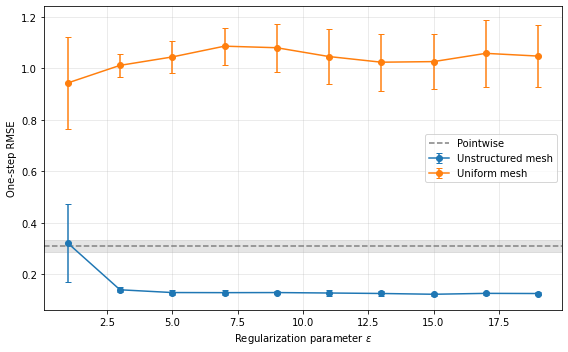

In [19]:
# NEW: Figure comparing three methods (0 = long-time W2, 1 = one-step RMSE)
metric = 1
plt.figure(figsize=(8, 5))

for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [[r[metric] for r in results[method][eps]] for eps in eps_values]
    means = [np.mean(e) if e else np.nan for e in errors]
    stds  = [np.std(e) if e else np.nan for e in errors]
    plt.errorbar(eps_values, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.array(results['pointwise'])[:, metric]
baseline_mean = baseline.mean()
baseline_std = baseline.std()

plt.axhline(baseline_mean, color='gray', linestyle='--', label='Pointwise')
plt.axhspan(
    baseline_mean - baseline_std,
    baseline_mean + baseline_std,
    color='gray',
    alpha=0.2
)

plt.xlabel(r'Regularization parameter $\varepsilon$')
plt.ylabel(r'Long-time $W_2$ reconstruction error' if metric == 0 else 'One-step RMSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()

In [ ]:
results

In [ ]:
errors

In [ ]:
metric = 1
plt.figure(figsize=(8, 5))
for method, label in [('adaptive', 'Unstructured mesh'), ('uniform', 'Uniform mesh')]:
    errors = [[r[metric] for r in results[method][eps]] for eps in eps_values]
    means = [np.mean(e) if e else np.nan for e in errors]
    stds = [np.std(e) if e else np.nan for e in errors]
    plt.errorbar(eps_values, means, yerr=stds, marker='o', capsize=3, label=label)

baseline = np.array(results['pointwise'])[:, metric]
plt.axhline(baseline.mean(), color='gray', linestyle='--', label='Pointwise')
plt.xlabel(r'Regularization parameter $\varepsilon$')
plt.ylabel(r'RMSE reconstruction error' if metric == 0 else 'One-step RMSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig('lorenz63_epsilon_ablation.png', dpi=200)
plt.show()